Saving server_response_time_raw.csv to server_response_time_raw.csv
   Subgroup_ID   Timestamp  Observation_No  Response_Time_ms
0            1  Day1_08h00               1             217.0
1            1  Day1_08h00               2             217.9
2            1  Day1_08h00               3             230.1
3            1  Day1_08h00               4             217.7
4            2  Day1_09h00               1             220.5
5            2  Day1_09h00               2             211.5
6            2  Day1_09h00               3             212.3
7            2  Day1_09h00               4             217.2
8            3  Day1_10h00               1             238.2
9            3  Day1_10h00               2             230.5

Tổng số dòng: 104
Số subgroup: 26
n (observation/subgroup) = 4
             Xbar_i   R_i
Subgroup_ID              
1            220.68  13.1
2            215.38   9.0
3            225.18  28.6
4            222.58  21.2
5            220.10  34.9
6            22

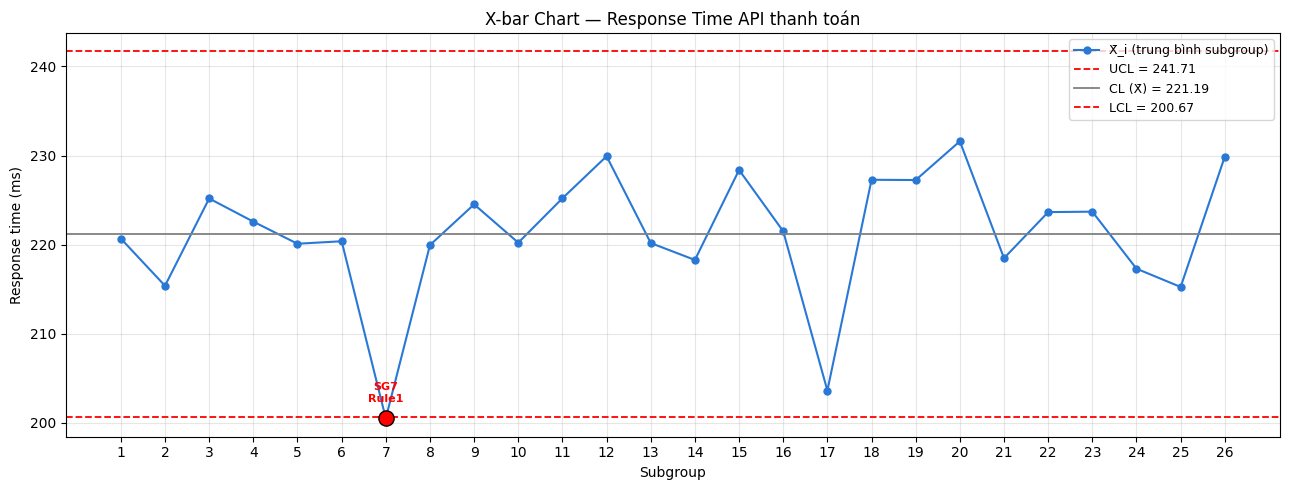

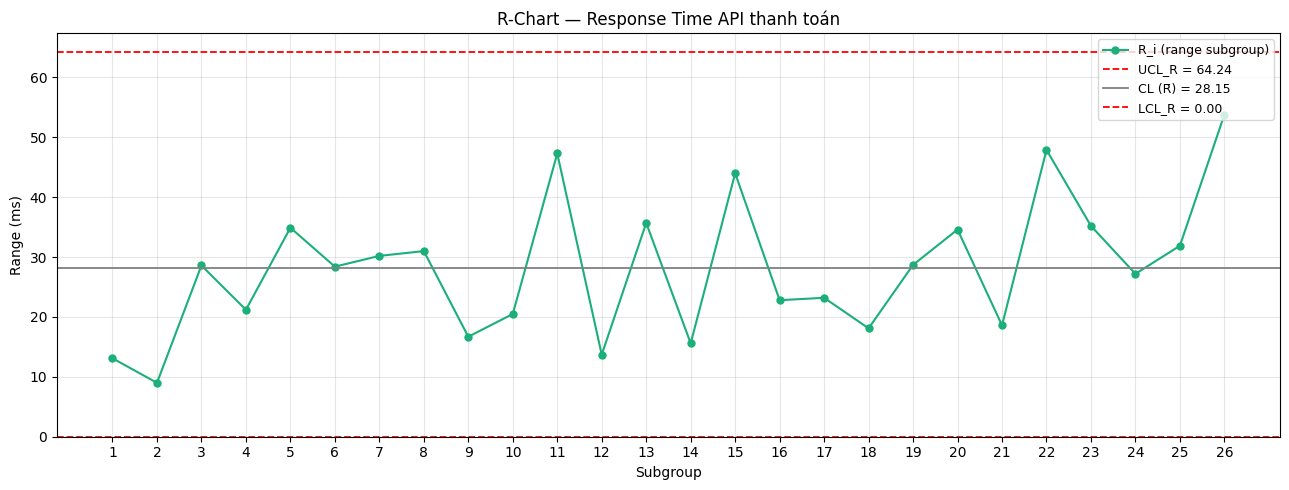

R-Chart: không có vi phạm (tất cả R_i nằm trong [LCL_R, UCL_R]).

KẾT LUẬN
Quy trình OUT OF CONTROL — phát hiện vi phạm:
  - Rule 1 (X-bar): 1 subgroup vi phạm -> [7]


In [1]:
# ============================================================
# X-BAR R CONTROL CHART — SERVER RESPONSE TIME
# Chạy trên Google Colab — copy từng cell hoặc chạy nguyên file
# ============================================================

# ---- CELL 1: Upload file CSV ----
from google.colab import files
uploaded = files.upload()  # chọn server_response_time_raw.csv khi được hỏi

# ---- CELL 2: Import thư viện ----
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---- CELL 3: Đọc dữ liệu ----
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
print(df.head(10))
print(f"\nTổng số dòng: {len(df)}")
print(f"Số subgroup: {df['Subgroup_ID'].nunique()}")

# ---- CELL 4: Tính X̄_i và R_i cho từng subgroup (BƯỚC 1) ----
grouped = df.groupby('Subgroup_ID')['Response_Time_ms']
xbar = grouped.mean().round(2)
rrange = (grouped.max() - grouped.min()).round(2)
n = grouped.count().iloc[0]  # số observation mỗi subgroup

summary = pd.DataFrame({'Xbar_i': xbar, 'R_i': rrange})
print(f"n (observation/subgroup) = {n}")
print(summary)

# ---- CELL 5: Tính X̄̄ và R̄ (BƯỚC 2) ----
Xbarbar = xbar.mean()
Rbar = rrange.mean()
k = len(xbar)  # số subgroup

print(f"\nSố subgroup k = {k}")
print(f"X̄̄ = (sum của {k} giá trị X̄_i) / {k} = {xbar.sum():.2f} / {k} = {Xbarbar:.4f} ms")
print(f"R̄  = (sum của {k} giá trị R_i)  / {k} = {rrange.sum():.2f} / {k} = {Rbar:.4f} ms")

# ---- CELL 6: Tra bảng hằng số theo n và tính control limit (BƯỚC 3, 4) ----
control_constants = {
    2: {'A2': 1.880, 'D3': 0,     'D4': 3.267},
    3: {'A2': 1.023, 'D3': 0,     'D4': 2.574},
    4: {'A2': 0.729, 'D3': 0,     'D4': 2.282},
    5: {'A2': 0.577, 'D3': 0,     'D4': 2.114},
}
A2 = control_constants[n]['A2']
D3 = control_constants[n]['D3']
D4 = control_constants[n]['D4']

# X-bar Chart limits
UCL_x = Xbarbar + A2 * Rbar
CL_x  = Xbarbar
LCL_x = Xbarbar - A2 * Rbar

# R-Chart limits
UCL_r = D4 * Rbar
CL_r  = Rbar
LCL_r = D3 * Rbar

print("=== X-bar Chart ===")
print(f"UCL = X̄̄ + A2×R̄ = {Xbarbar:.4f} + {A2}×{Rbar:.4f} = {UCL_x:.4f} ms")
print(f"CL  = X̄̄              = {CL_x:.4f} ms")
print(f"LCL = X̄̄ - A2×R̄ = {Xbarbar:.4f} - {A2}×{Rbar:.4f} = {LCL_x:.4f} ms")

print("\n=== R-Chart ===")
print(f"UCL = D4×R̄ = {D4}×{Rbar:.4f} = {UCL_r:.4f} ms")
print(f"CL  = R̄         = {CL_r:.4f} ms")
print(f"LCL = D3×R̄ = {D3}×{Rbar:.4f} = {LCL_r:.4f} ms")

# Bảng tóm tắt
print("\n=== BẢNG TÓM TẮT ===")
summary_table = pd.DataFrame({
    'Thống kê': ['X̄̄', 'R̄', 'UCL (X-bar)', 'CL (X-bar)', 'LCL (X-bar)',
                 'UCL (R)', 'CL (R)', 'LCL (R)'],
    'Giá trị (ms)': [Xbarbar, Rbar, UCL_x, CL_x, LCL_x, UCL_r, CL_r, LCL_r]
}).round(2)
print(summary_table.to_string(index=False))

# ---- CELL 7: RULE 1 — 3-sigma (BƯỚC 2 phần c) ----
print("\n" + "="*60)
print("RULE 1 (3-sigma) — kiểm tra từng subgroup")
print("="*60)

rule1_violations = []
for sg in xbar.index:
    val = xbar[sg]
    if val > UCL_x:
        rule1_violations.append((sg, val, 'VƯỢT UCL'))
        print(f"Subgroup {sg}: X̄ = {val:.2f} > UCL = {UCL_x:.2f}  -> VI PHẠM (vượt trên)")
    elif val < LCL_x:
        rule1_violations.append((sg, val, 'DƯỚI LCL'))
        print(f"Subgroup {sg}: X̄ = {val:.2f} < LCL = {LCL_x:.2f}  -> VI PHẠM (dưới)")

if not rule1_violations:
    print("Không có vi phạm Rule 1.")
else:
    print(f"\n>>> Tổng số vi phạm Rule 1: {len(rule1_violations)}")
    for sg, val, kind in rule1_violations:
        print(f"    Subgroup {sg}: X̄={val:.2f} ms ({kind})")

# ---- CELL 8: RULE 2 — Rule of 8 (cửa sổ trượt) ----
print("\n" + "="*60)
print("RULE 2 (Rule of 8) — quét cửa sổ trượt 8 subgroup liên tiếp")
print("="*60)

sides = {sg: ('above' if xbar[sg] > CL_x else 'below') for sg in xbar.index}
sg_list = list(xbar.index)

rule2_violations = []
for start_idx in range(len(sg_list) - 8 + 1):
    window = sg_list[start_idx:start_idx + 8]
    window_sides = [sides[sg] for sg in window]
    if all(s == 'above' for s in window_sides):
        rule2_violations.append((window[0], window[-1], 'above', window))
    elif all(s == 'below' for s in window_sides):
        rule2_violations.append((window[0], window[-1], 'below', window))

if not rule2_violations:
    print("Không có vi phạm Rule 2 (không có 8 điểm liên tiếp cùng phía).")
else:
    print(f">>> Tổng số cửa sổ vi phạm: {len(rule2_violations)}")
    for s, e, side, window in rule2_violations:
        print(f"    Cửa sổ [{s}-{e}]: tất cả {len(window)} subgroup nằm {side} center line -> {window}")

# Tập hợp tất cả subgroup bị đánh dấu (để tô màu trên chart)
rule1_sg_set = set(sg for sg, _, _ in rule1_violations)
rule2_sg_set = set()
for s, e, side, window in rule2_violations:
    rule2_sg_set.update(window)

# ---- CELL 9: Vẽ X-bar Chart ----
fig, ax = plt.subplots(figsize=(13, 5))

sg_ids = xbar.index.values
xbar_vals = xbar.values

ax.plot(sg_ids, xbar_vals, marker='o', color='#2a78d6', linewidth=1.5,
        markersize=5, zorder=2, label='X̄_i (trung bình subgroup)')

# Tô màu các điểm vi phạm Rule 1
for sg in rule1_sg_set:
    ax.scatter(sg, xbar[sg], color='red', s=120, zorder=5,
               edgecolor='black', linewidth=1)
    ax.annotate(f'SG{sg}\nRule1', (sg, xbar[sg]),
                textcoords="offset points", xytext=(0, 12),
                ha='center', fontsize=8, color='red', fontweight='bold')

# Tô màu nền các cửa sổ vi phạm Rule 2 (nếu có)
for s, e, side, window in rule2_violations:
    ax.axvspan(s - 0.3, e + 0.3, color='orange', alpha=0.15, zorder=0)

ax.axhline(UCL_x, color='red', linestyle='--', linewidth=1.3, label=f'UCL = {UCL_x:.2f}')
ax.axhline(CL_x, color='gray', linestyle='-', linewidth=1.3, label=f'CL (X̄̄) = {CL_x:.2f}')
ax.axhline(LCL_x, color='red', linestyle='--', linewidth=1.3, label=f'LCL = {LCL_x:.2f}')

ax.set_xlabel('Subgroup')
ax.set_ylabel('Response time (ms)')
ax.set_title('X-bar Chart — Response Time API thanh toán')
ax.set_xticks(sg_ids)
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('xbar_chart.png', dpi=150)
plt.show()

# ---- CELL 10: Vẽ R-Chart ----
fig, ax = plt.subplots(figsize=(13, 5))

r_vals = rrange.values

ax.plot(sg_ids, r_vals, marker='o', color='#1baf7a', linewidth=1.5,
        markersize=5, zorder=2, label='R_i (range subgroup)')

# Đánh dấu nếu có điểm vượt UCL_r hoặc dưới LCL_r
r_violations = []
for sg in sg_ids:
    if rrange[sg] > UCL_r or rrange[sg] < LCL_r:
        r_violations.append(sg)
        ax.scatter(sg, rrange[sg], color='red', s=120, zorder=5,
                   edgecolor='black', linewidth=1)

ax.axhline(UCL_r, color='red', linestyle='--', linewidth=1.3, label=f'UCL_R = {UCL_r:.2f}')
ax.axhline(CL_r, color='gray', linestyle='-', linewidth=1.3, label=f'CL (R̄) = {CL_r:.2f}')
ax.axhline(LCL_r, color='red', linestyle='--', linewidth=1.3, label=f'LCL_R = {LCL_r:.2f}')

ax.set_xlabel('Subgroup')
ax.set_ylabel('Range (ms)')
ax.set_title('R-Chart — Response Time API thanh toán')
ax.set_xticks(sg_ids)
ax.set_ylim(bottom=0)
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('r_chart.png', dpi=150)
plt.show()

if r_violations:
    print(f"R-Chart: vi phạm tại subgroup {r_violations}")
else:
    print("R-Chart: không có vi phạm (tất cả R_i nằm trong [LCL_R, UCL_R]).")

# ---- CELL 11: Kết luận tổng thể ----
print("\n" + "="*60)
print("KẾT LUẬN")
print("="*60)
total_violations = len(rule1_violations) + len(rule2_violations) + len(r_violations)
if total_violations == 0:
    print("Quy trình IN CONTROL — không có vi phạm Rule 1, Rule 2 trên cả 2 chart.")
else:
    print("Quy trình OUT OF CONTROL — phát hiện vi phạm:")
    if rule1_violations:
        print(f"  - Rule 1 (X-bar): {len(rule1_violations)} subgroup vi phạm -> {[sg for sg,_,_ in rule1_violations]}")
    if rule2_violations:
        print(f"  - Rule 2 (X-bar): {len(rule2_violations)} cửa sổ vi phạm")
    if r_violations:
        print(f"  - R-Chart vi phạm: subgroup {r_violations}")